## Synchronization of neurons: two synaptically coupled Hodgkin-Huxley models

#### Letizia Di Pietro, Benedicta Scarongella, Antonio Troiano

30561 STOCHASTIC PROCESSES AND SIMULATION IN NATURAL SCIENCES - Group Project

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

The aim of this project is to simulate a system of two synaptically coupled Hodgkin-Huxley models, and investigate the behavior as a function of strength and characteristics of synaptic coupling.  

The outline of the work is the following:
- **Step 1**: Explain and analyze in broad terms the biological background to understand the setting in which we are operating.
- **Step 2**: Describe the Hodgkin-Huxley Model and simulate the dynamics of a single neuron reacting to an external current.
- **Step 3**: Present and simulate the dynamics of two coupled neurons, examining how their interaction changes by varying the external input and the strength of the coupling parameter.
- **Step 4**: Compare the different numerical methods of Euler, Runge-Kutta2 and Runge-Kutta4 to analyze the efficiency of the solver.

## Biological Background

Neurons, specialized cellular components of the nervous system, serve as the primary units for transmitting signals throughout the body.
The cell membrane is semipermeable and maintains a distinct separation between the internal fluid, negatively charged with high concentration of potassium ions, and the external fluid which is positively charged and rich in sodium ions.
When a neuron is at rest, there is a potential difference across its membrane.  
The membrane potential results from the selective permeability of the neuronal membrane to different ions, primarily sodium (Na⁺) and potassium (K⁺). These ionic fluxes are regulated by voltage-gated ion channels, whose conductance changes dynamically in response to variations in the membrane voltage.
In addition to active ionic currents, neurons exhibit passive ‘leak’ currents due to always-open channels, contributing to the resting membrane potential.

Neurons are excitable cells that communicate using electrical signals called **Action Potentials**. An Action Potential is a brief, rapid reversal of the cell's voltage, generated when a stimulus reaches a threshold. This signal is caused by the quick opening and closing of voltage-gated ion channels in the neuron's membrane.

## Hodgkin-Huxley Model for Single Neuron

The Hodgkin-Huxley Model explains the Action Potential as a sequence of events triggered when a stimulus reaches a threshold. This event is caused by the opening and closing of two types of voltage-gated ion channels:
- Transient Channels ($\text{Na}^+$): These open quickly to start the signal (using an activation gate of probability $m$) but then rapidly close (using an inactivation gate of probability $h$).
- Persistent Channels ($\text{K}^+$): These open slowly to end the signal and restore the resting state. They are controlled by the gating variable $n$. 

This carefully controlled movement of gates changes the membrane potential, generating the electrical impulse.

Now that we explained the mechanism behind the electrical impulse, we can move on to the actual Hodgkin-Huxley model.

### The model

The model uses four differential equations, that model the ionic flow of the neuron, to compute the membrane potential. The authors of the model studied the ionic flow by inserting an electrode into the cell and inputting a current to measure how the flow of ions and cell membrane change based on it.

The four ODEs are:
$$
C_m \frac{dV}{dt}
= I_{\text{ext}}
- \bar{g}_{Na} \, m^3 h \, (V - E_{Na})
- \bar{g}_K \, n^4 \, (V - E_{K})
- \bar{g}_L \, (V - E_{L})
\tag{1}
$$

$$
\frac{dm}{dt}
= \alpha(\nu)_m \, (1 - m)
- \beta(\nu)_m \, m
\tag{2}
$$

$$
\frac{dh}{dt}
= \alpha(\nu)_h \, (1 - h)
- \beta(\nu)_h \, h
\tag{3}
$$

$$
\frac{dn}{dt}
= \alpha(\nu)_n \, (1 - n)
- \beta(\nu)_n \, n
\tag{4}
$$


Let's exploit the ODEs:

1. In Equation $(1)$ we are interested in $\frac{dV}{dt}$ which is the change in the displacement of the membrane potential from its resting value with respect to time.  
$C_m$ is the membrane capacity which is assumed to be constant.  
$I_{\text{ext}}$ is the simulation current per unit area. It is an input current meaning that it is coming from an outside source.   
The other three terms on the right hand side of the equation represent three different ionic current densites measured (sodium, potassium and leakage).
The $g_i$ ($i \in \{N_a, K, L\}$) are the maximum membrane conductances per ion, while $E_i$ are the potential values where there is no net flow of the corresponding ion across the membrane (the reversal potential).  
$h, m, n$ instead are the voltage-dependent conductance variables, also known as gating variables.

2. Equations $(2), (3)\ \text{and}\ (4)$ represent the dynamics of the gating variables.  
Here, $\alpha$ and $\beta$ are rate constant that governs the rate at which closed gates transition to an open state and the rate at which open gates transition to the closed state. 




In particular, the rate constants $\alpha$ and $\beta$ in physiological setting are given by:
$$
\alpha(\nu)_m = \frac{0.1(V + 40)}{1 - \exp\!\left(-\frac{V + 40}{10}\right)}, \qquad
\alpha(\nu)_h = 0.07 \exp\!\left( -\frac{(V + 65)}{20} \right), \qquad
\alpha(\nu)_n = \frac{0.01(V + 55)}{1 - \exp\!\left(-\frac{V + 55}{10}\right)}
$$

$$
\beta(\nu)_m = 4 \exp\!\left(-\frac{V + 65}{18} \right), \qquad
\beta(\nu)_h = \frac{1}{\exp\!\left(-\frac{V + 35}{10}\right) + 1}, \qquad
\beta(\nu)_n = 0.125 \exp\!\left( -\frac{(V + 65)}{80} \right)
$$


### Global Constants

Let's present the parameters we will use for our simulations.  
In much of the Hodgkin–Huxley literature, the membrane potential is expressed relative to a zero reference level. In this work, however, we adopt a more physiological convention so that the resting potential corresponds to −65 mV. All parameters and equilibrium values are therefore scaled accordingly with respect to this reference.

In [2]:
C_m   = 1.0      # uF/cm^2
G_Na  = 120.0    # mS/cm^2
G_K   = 36.0     # mS/cm^2
G_m   = 0.3     # mS/cm^2


E_Na  = 50  # mV
E_K   = -77 # mV
V_rest = -54.4 # mV (leak energy E_L)

### Empirical Equations

Here, the empirical equations for the rate constants $\alpha$ and $\beta$ scaled in order to work in the physiological setting.

In [3]:
def alpha_m(V):
    return 0.1 * (V + 40.0) / (1.0 - np.exp(-(V + 40.0) / 10.0))

def beta_m(V):
    return 4.0 * np.exp(-(V + 65.0) / 18.0)

def alpha_h(V):
    return 0.07 * np.exp(-(V + 65.0)/20.0)

def beta_h(V):
    return 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0))

def alpha_n(V):
    return 0.01 * (V + 55.0) / (1.0 - np.exp(-(V + 55.0) / 10.0))

def beta_n(V):
    return 0.125 * np.exp(-(V + 65.0) / 80.0)

### ODEs 

Finally, let's write the set of four differental equations defining the model.

In [4]:
# ODE of membrane potential

def V_dot(V, n, m, h, I_in, 
          G_Na, G_K, G_m, E_Na, E_K, V_rest, C_m):
    
    return (G_Na * m**3 * h * (E_Na - V) +
            G_K * n**4 * (E_K - V) +
            G_m * (V_rest - V) +
            I_in) / C_m

# ODEs of gating variables

def n_dot(n, V):
    return alpha_n(V) * (1 - n) - beta_n(V) * n

def m_dot(m, V):
    return alpha_m(V) * (1 - m) - beta_m(V) * m

def h_dot(h, V):
    return alpha_h(V) * (1 - h) - beta_h(V) * h

## Simulation of a Single Hodgkin–Huxley Neuron

After introducing the biological mechanisms behind action potentials and presenting the Hodgkin–Huxley model equations, we now turn to the numerical simulation of a **single neuron** responding to an external input current.

The external current is defined below and it can be of two types:
- **Constant**: it has the same value $I_0$ at each instant of time $t$
- **Non-Constant**: the current is a step function depending on the specific time 

We will run many simulations and investigate what happens for different values of $I_\text{ext}$. 

In [5]:
def I_func(t, constant, I0):
    
    t = np.array(t)
    I = np.zeros_like(t, dtype=float)

    # Case: constant current
    if constant == True:
        I[:] = I0
        return I

    # Case: non constant current (step function) 
    I[(t >= 0) & (t < 20)] = 2
    I[(t >= 30) & (t < 40)] = 3

    return I


### Numerical Integration

To solve the ODE system, we start with an explicit Euler method with a small time step, and apply it to a range of external currents. The resulting voltage traces allow us to visualize the threshold phenomenon and the firing behavior of the single neuron, forming the foundation for the next section on **coupled neurons**.

The forward Euler method is a first-order numerical scheme used to approximate the solution of ordinary differential equations. At each time step, the derivative $f(y,t)$ is evaluated at the current point and used to advance the solution linearly:

$$
y_{n+1} = y_n + \Delta t\, f(y_n, t_n).
$$


In [6]:
def euler(f, y0, t0, t1, dt, I_ext, *args):
  
    t = np.arange(t0, t1 + dt, dt)
    y = np.zeros((len(t), len(y0)), dtype=float)

    y[0, :] = y0

    for i in range(len(t) - 1):
        I_in = I_ext[i]       
        dy = f(y[i], I_in, *args)
        y[i + 1] = y[i] + dt * dy

    return t, y


The function `hh_system` defines the full set of Hodgkin–Huxley differential equations describing the time evolution of the membrane voltage and the gating variables.  
Given the current state vector  
$$
y = [V, n, m, h],
$$
and the model parameters, the function computes the derivatives
$$
\frac{dV}{dt},\quad \frac{dn}{dt},\quad \frac{dm}{dt},\quad \frac{dh}{dt},
$$
using the standard HH ionic currents and gating kinetics.  

The function then returns these four derivatives as a vector, so numerical solvers can integrate the system over time.


In [7]:
def hh_system(y, I_in,
              G_Na, G_K, G_m,
              E_Na, E_K, V_rest, C_m):
    
    V, n, m, h = y

    dn = n_dot(n, V)
    dm = m_dot(m, V)
    dh = h_dot(h, V)

    dV = V_dot(V, n, m, h, I_in,
               G_Na, G_K, G_m, E_Na, E_K, V_rest, C_m)

    return np.array([dV, dn, dm, dh])



### Initial State

Before integrating the ODE system, we set the neuron in its physiological **resting state**.  
For the Hodgkin–Huxley model, the resting potential is approximately:

$$
V_0 = -65 \,\text{mV}
$$

and the gating variables \(n, m, h\) are initialized at their **steady-state values** computed at this voltage:

$$
n_0 = n_\infty(V_0), \qquad
m_0 = m_\infty(V_0), \qquad
h_0 = h_\infty(V_0)
$$

where, for each gating variable $x \in \{n, m, h\}$:

$$
x_\infty(V) = \frac{\alpha_x(V)}{\alpha_x(V) + \beta_x(V)}.
$$

These values match the classical resting-state parameters used in Hodgkin–Huxley simulations and ensure that the model starts from a stable equilibrium.

In [8]:

V0 = -65.0
n0 = 0.3176
m0 = 0.0529
h0 = 0.5961

y0 = [V0, n0, m0, h0]

t0 = 0.0
t1 = 300.0
dt = 0.001

t = np.arange(t0, t1 + dt, dt)



### Test Cases:

### Membrane Potential Without External Stimulation

In this simulation the external current is set to zero and the Hodgkin–Huxley equations are integrated starting from the resting state of the neuron. 

The initial conditions (V = -65 mV and the corresponding gating variables) represent the physiological equilibrium of the model.

Since the neuron is not receiving any external input, the membrane potential remains close to its resting value. The small initial fluctuation is not a biological effect but a numerical transient caused by the combination of slightly imperfect initial conditions and the discretization error of the explicit Euler method. After a few milliseconds the system settles back to rest.

You may notice that the y-axis shows very small numbers together with an offset (for example, “-6.4999e1”). This is simply a plotting convention: the axis shows the deviation from a large constant value, while the offset represents the actual resting potential. In reality, the voltage is stable around -65 mV, exactly as expected.

Overall, the plot confirms that:
1. the initial conditions correctly place the neuron at rest,
2. without a stimulus the model does not generate action potentials,
3. with a sufficiently small time step the Euler solver maintains the steady state.

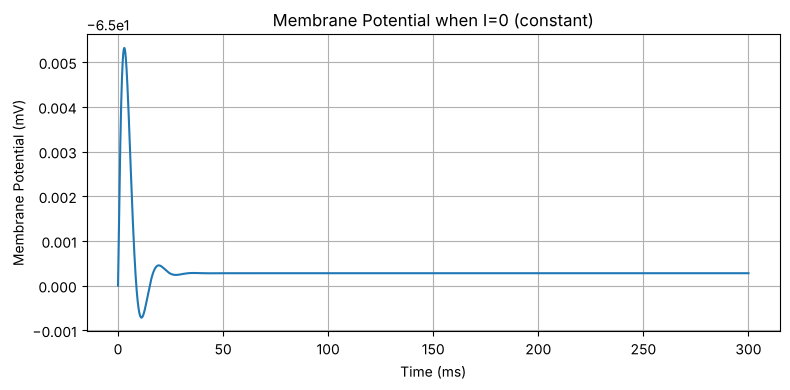

In [9]:
I_vec = I_func(t, True, 0)      

t, y = euler(
    hh_system,
    y0,
    t0, t1, dt,
    I_vec,               
    G_Na, G_K, G_m,
    E_Na, E_K, V_rest, C_m
)

V_traj = y[:, 0]  


plt.figure(figsize=(8, 4))
plt.plot(t, V_traj)
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")
plt.title("Membrane Potential when I=0 (constant)")
plt.grid(True)
plt.tight_layout()
plt.show()




### Membrane Potential With a Strong Negative External Current

In this simulation the neuron receives a constant negative input current.  
A negative current forces the membrane potential downward, pulling it far below its normal
resting value.

Because the Hodgkin–Huxley model is not designed to represent extremely strong
hyperpolarizing inputs, the membrane potential moves toward a very negative and
non-physiological value. This is expected when applying a large negative current: the model is
simply following the ionic currents implied by the equations.

As a result:

1. the neuron does not produce action potentials,
2. the membrane potential rapidly decreases and then stabilizes at a very negative value,
3. this behavior is purely a mathematical consequence of the model equations and does not
represent realistic biological conditions.

The plot clearly shows this effect: after the start of the simulation, the voltage drops steeply and
then settles on a flat line around a very negative value, with no signs of spiking activity.

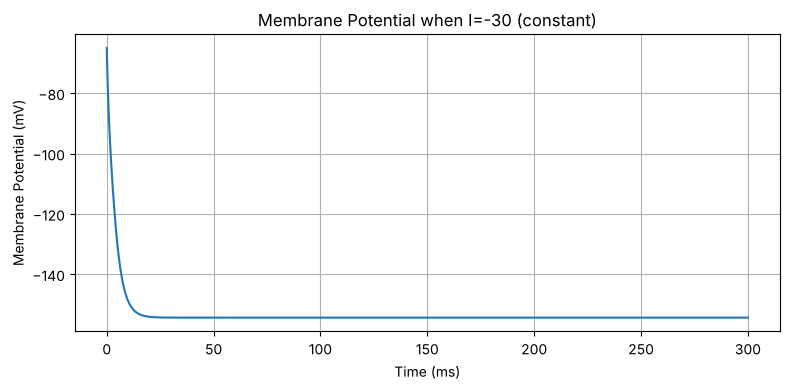

In [10]:
I_vec = I_func(t, True, -30)      

t, y = euler(
    hh_system,
    y0,
    t0, t1, dt,
    I_vec,                
    G_Na, G_K, G_m,
    E_Na, E_K, V_rest, C_m
)

V_traj = y[:, 0]  


plt.figure(figsize=(8, 4))
plt.plot(t, V_traj)
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")
plt.title("Membrane Potential when I=-30 (constant)")
plt.grid(True)
plt.tight_layout()
plt.show()


### Membrane Potential With a Small Positive External Current

When the input current is set to a small value such as I=2 (left figure), the neuron does not reach the activation threshold of the sodium channels. As a result, the membrane potential only shows a brief transient and then relaxes back to its resting value without generating any action potential. This behavior is characteristic of subthreshold stimulation, where the input is insufficient to trigger a spike.

In the other simulation (right figure) the neuron receives a small positive constant current. This input
is slightly above the threshold required to trigger an action potential.

At the beginning of the simulation, the membrane potential depolarizes quickly and reaches
a clear spike. This is the typical action potential generated by the Hodgkin–Huxley model when
the stimulus is strong enough to open sodium channels.

After a sharp spike at the start, the external current is not large enough to sustain repetitive firing. The
neuron therefore returns to its resting level and stays there for the remainder of the simulation.

This is the expected response for a near-threshold current: one spike is produced, but no
repetitive spiking occurs

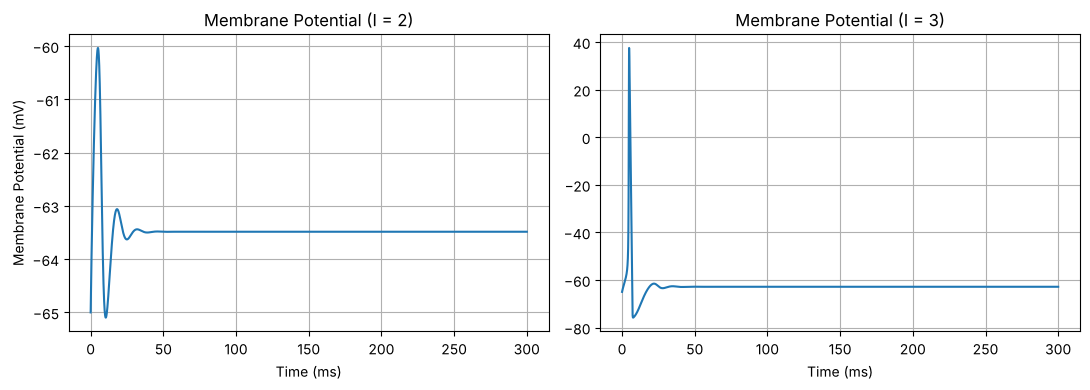

In [11]:
I_vec_2 = I_func(t, True, 2)
I_vec_3 = I_func(t, True, 3)

t, y_neg2 = euler(
    hh_system,
    y0,
    t0, t1, dt,
    I_vec_2,
    G_Na, G_K, G_m,
    E_Na, E_K, V_rest, C_m
)
V_neg2 = y_neg2[:, 0]

t, y_neg3 = euler(
    hh_system,
    y0,
    t0, t1, dt,
    I_vec_3,
    G_Na, G_K, G_m,
    E_Na, E_K, V_rest, C_m
)
V_neg3 = y_neg3[:, 0]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(t, V_neg2)
ax[0].set_title("Membrane Potential (I = 2)")
ax[0].set_xlabel("Time (ms)")
ax[0].set_ylabel("Membrane Potential (mV)")
ax[0].grid(True)

ax[1].plot(t, V_neg3)
ax[1].set_title("Membrane Potential (I = 3)")
ax[1].set_xlabel("Time (ms)")
ax[1].grid(True)

plt.tight_layout()
plt.show()

### Gating variables 

Here we plot the three gating variables n, m and h for the same simulations.
They represent the probabilistic opening of potassium channels (n) and the
activation and inactivation of sodium channels (m and h).

For the subthreshold current (I=2), the input is not strong enough to activate the sodium channels.
All three gating variables remain close to their resting values, showing only a small transient before settling back.
This confirms that the neuron stays below threshold and does not generate an action potential.

For the suprathreshold current (I=3), the gating variables behave as expected during a spike. The right figure shows that:
- m increases very quickly during the spike (fast activation of sodium channels),
- h decreases during the spike (sodium channels start to inactivate),
- n increases more slowly and stays high for longer (delayed activation of potassium).

Together, these dynamics explain why the membrane potential rises rapidly and then
comes back down after each spike.

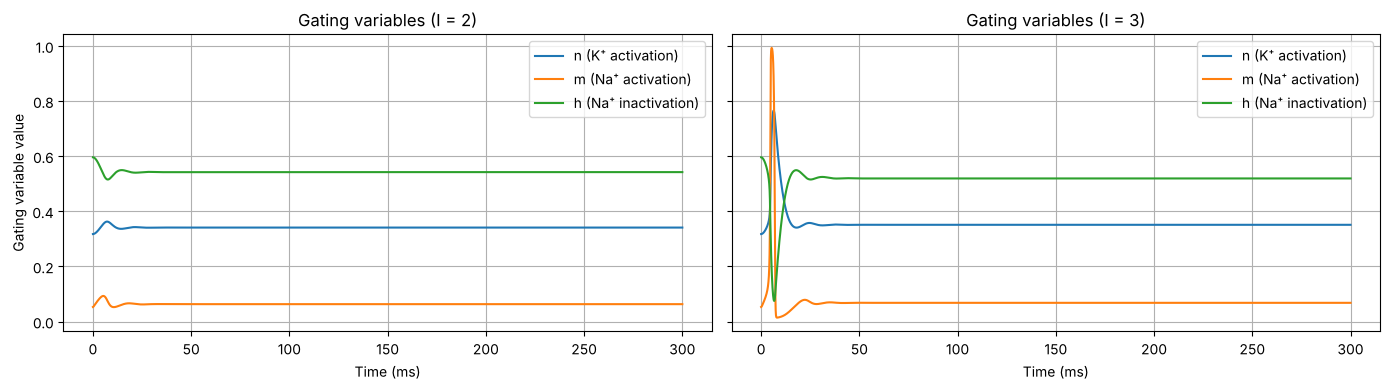

In [12]:

V_neg2 = y_neg2[:, 0]
n_neg2 = y_neg2[:, 1]
m_neg2 = y_neg2[:, 2]
h_neg2 = y_neg2[:, 3]

V_neg3 = y_neg3[:, 0]
n_neg3 = y_neg3[:, 1]
m_neg3 = y_neg3[:, 2]
h_neg3 = y_neg3[:, 3]



fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)


ax[0].plot(t, n_neg2, label="n (K⁺ activation)")
ax[0].plot(t, m_neg2, label="m (Na⁺ activation)")
ax[0].plot(t, h_neg2, label="h (Na⁺ inactivation)")
ax[0].set_title("Gating variables (I = 2)")
ax[0].set_xlabel("Time (ms)")
ax[0].set_ylabel("Gating variable value")
ax[0].grid(True)
ax[0].legend()

ax[1].plot(t, n_neg3, label="n (K⁺ activation)")
ax[1].plot(t, m_neg3, label="m (Na⁺ activation)")
ax[1].plot(t, h_neg3, label="h (Na⁺ inactivation)")
ax[1].set_title("Gating variables (I = 3)")
ax[1].set_xlabel("Time (ms)")
ax[1].grid(True)
ax[1].legend()

plt.tight_layout()
plt.show()


### Membrane Potential With a Strong Positive External Current

In this simulation the neuron receives a relatively strong constant current. This
input is well above the threshold required to trigger spiking, and as a result the neuron enters
a regime of repetitive firing.

At the start of the simulation, the membrane potential depolarizes quickly and produces an
action potential. Unlike the previous case with weaker external current, the stimulus is now strong enough
to maintain the cycle of activation and recovery of the sodium and potassium channels.
Because of this, the neuron keeps firing spikes at regular intervals for the entire duration of
the simulation.

The plot clearly shows:
1. a periodic train of action potentials,
2. a stable inter-spike interval,
3. no tendency to return to rest as long as the external current remains active.

This behavior is typical of the Hodgkin–Huxley model when the injected current is large
enough to sustain continuous repetitive spiking.

### Gating Variables During Repetitive Spiking

With a strong constant external current, the neuron fires repeatedly. This plot shows how the three gating variables behave during this continuous spiking.

Each action potential corresponds to a full cycle in these variables:

1. **m increases very quickly at the start of each spike.**  
   This fast activation of sodium channels pushes the membrane potential upward.

2. **h decreases during the spike.**  
   Sodium inactivation gradually turns off the sodium current, helping end the spike.

3. **n rises more slowly and peaks after m.**  
   Potassium channels open with a delay, producing the outward current that brings the membrane potential back down.

4. Between spikes, all three variables return to intermediate values before the next cycle begins.

Because the external current is strong enough to keep the neuron above threshold, this cycle repeats regularly, producing a stable, periodic train of action potentials.

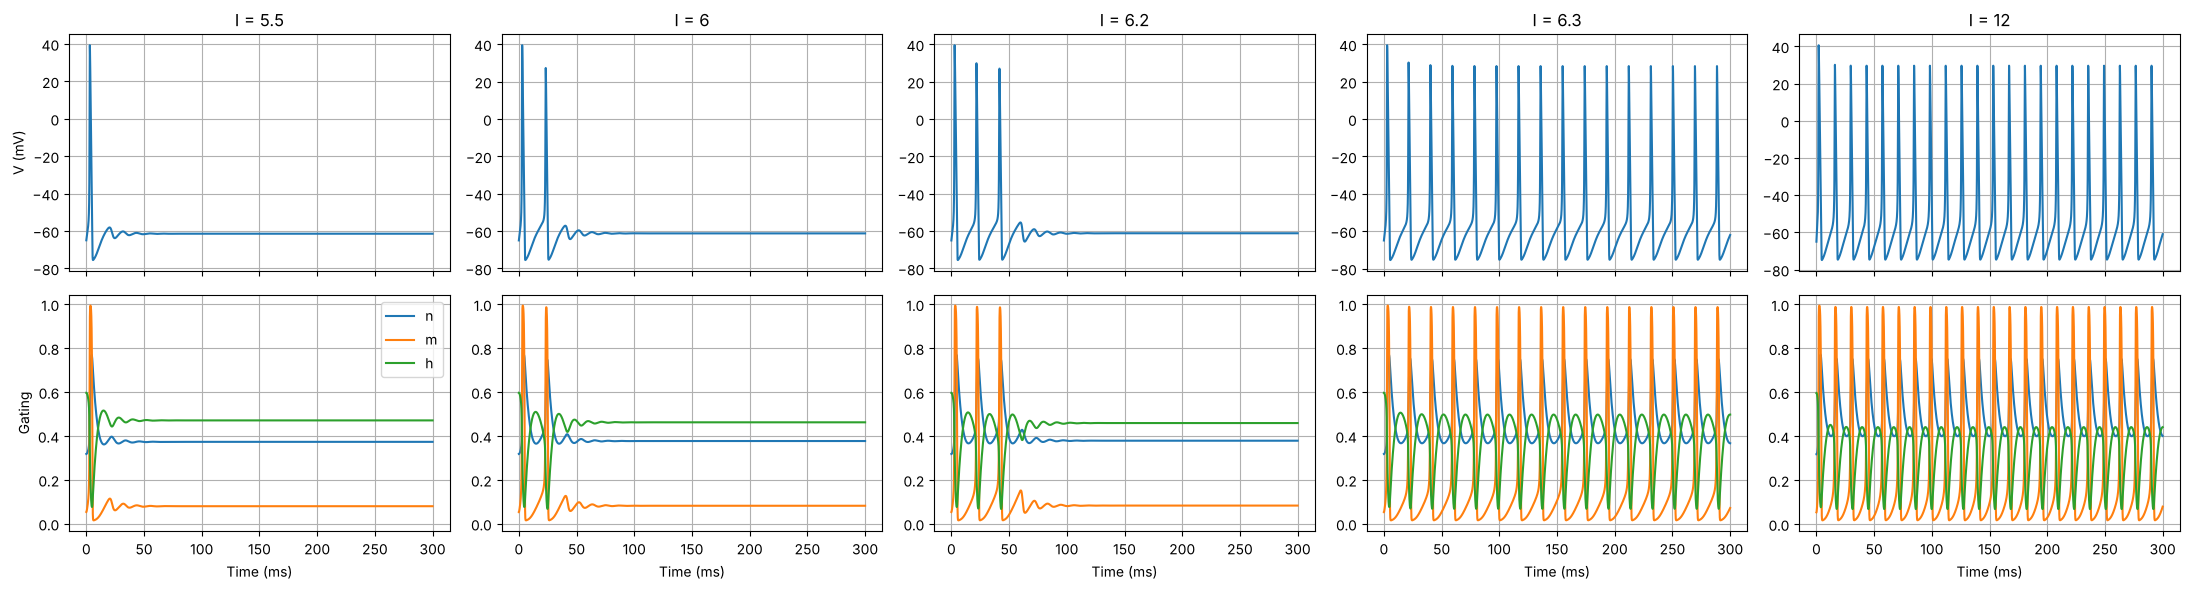

In [13]:
# Input currents to test
I_values = [5.5, 6, 6.2, 6.3, 12]

# 2 x 5 grid of panels
fig, ax = plt.subplots(2, len(I_values), figsize=(22, 6), sharex=True)

for i, I_val in enumerate(I_values):

    # Constant current
    I_vec = I_func(t, True, I_val)
    
    # Simulation
    t, y = euler(
        hh_system,
        y0,
        t0, t1, dt,
        I_vec,
        G_Na, G_K, G_m,
        E_Na, E_K, V_rest, C_m
    )
    
    # Extract the state variables
    V_traj = y[:, 0]
    n_traj = y[:, 1]
    m_traj = y[:, 2]
    h_traj = y[:, 3]
    
    # --------------------------
    #    ROW 1: MEMBRANE POTENTIAL
    # --------------------------
    ax[0, i].plot(t, V_traj)
    ax[0, i].set_title(f"I = {I_val}")
    ax[0, i].set_ylabel("V (mV)" if i == 0 else "")
    ax[0, i].grid(True)
    
    # --------------------------
    #    ROW 2: GATING VARIABLES
    # --------------------------
    ax[1, i].plot(t, n_traj, label="n")
    ax[1, i].plot(t, m_traj, label="m")
    ax[1, i].plot(t, h_traj, label="h")
    ax[1, i].set_xlabel("Time (ms)")
    ax[1, i].set_ylabel("Gating" if i == 0 else "")
    ax[1, i].grid(True)
    
    # Legend only in the first panel of the second row
    if i == 0:
        ax[1, i].legend()

plt.tight_layout()
plt.show()


### Membrane Potential With a Step-Function External Current

In this simulation the external current is not constant. It follows a step pattern:
- from t = 0 to t = 20 ms, the current is 2 (subthreshold),
- from t = 20 to t = 30 ms, the current returns to zero,
- from t = 30 to t = 40 ms, the current increases to 3 (slightly above threshold),
- for the rest of the simulation the current is zero again.

This type of input allows us to see how the neuron reacts to stimuli that appear only for a
limited amount of time.

The plot shows the following behavior:
1. During the first step (current = 2), the input is not strong enough to trigger a spike.
   The voltage shows only small oscillations around the resting value.
2. When the stronger step of current = 3 is applied, the stimulus crosses the threshold and the
   neuron produces a single action potential.
3. After the spike, the current returns to zero and the membrane potential falls back to its
   resting level, where it remains for the rest of the simulation.

This result matches the expected behavior of the Hodgkin–Huxley model: a near-threshold
stimulus applied only briefly can generate exactly one spike, but not sustained firing.

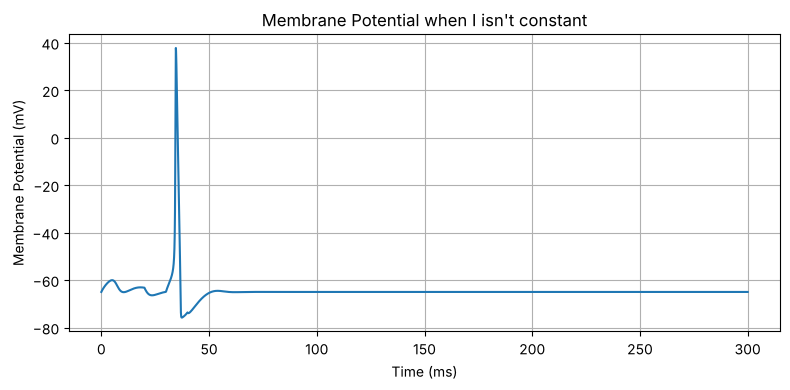

In [14]:
I_vec = I_func(t, False, 0)      

t, y = euler(
    hh_system,
    y0,
    t0, t1, dt,
    I_vec,                 
    G_Na, G_K, G_m,
    E_Na, E_K, V_rest, C_m
)

V_traj = y[:, 0]  


plt.figure(figsize=(8, 4))
plt.plot(t, V_traj)
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")
plt.title("Membrane Potential when I isn't constant")
plt.grid(True)
plt.tight_layout()
plt.show()

### Gating Variables During a Step-Current Input

This plot shows how the gating variables respond to a non-constant external current.

During the stronger current step, the neuron briefly reaches the threshold and fires a single action potential. The gating variables reflect this:

1. **m rises sharply during the spike**, showing fast activation of sodium channels.
2. **h decreases at the same moment**, representing sodium inactivation that helps bring the spike to an end.
3. **n increases more slowly**, indicating the delayed activation of potassium channels that repolarize the membrane.

Once the spike is over and the input current drops back to zero, all three gating variables gradually return toward their resting values. Since the current is not strong enough to sustain repetitive firing, the neuron generates only one spike, after which the gating variables settle into stable levels.

This plot shows clearly how the gating dynamics react to a short, above-threshold stimulus and return to rest once the stimulus is removed.

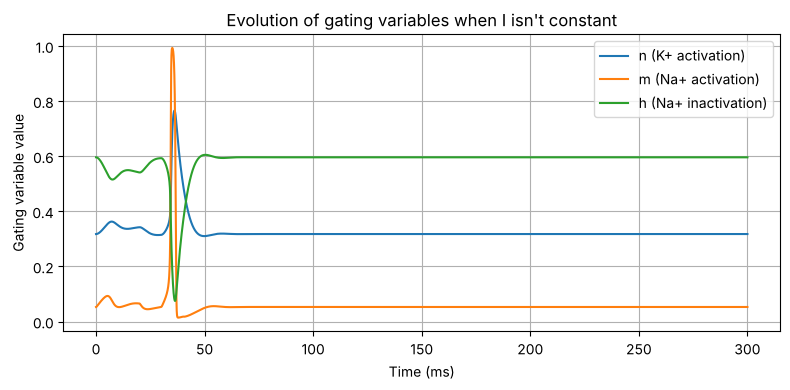

In [15]:
V_traj = y[:, 0]
n_traj = y[:, 1]
m_traj = y[:, 2]
h_traj = y[:, 3]

plt.figure(figsize=(8, 4))
plt.plot(t, n_traj, label="n (K+ activation)")
plt.plot(t, m_traj, label="m (Na+ activation)")
plt.plot(t, h_traj, label="h (Na+ inactivation)")
plt.xlabel("Time (ms)")
plt.ylabel("Gating variable value")
plt.title("Evolution of gating variables when I isn't constant")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## System of two coupled neurons 

In order to study the effect of electrical coupling on the membrane dynamics,
we consider a system of two Hodgkin–Huxley neurons interconnected
through a gap-junction–like coupling.  
Only the first neuron receives an external input current, while the second neuron
is driven exclusively through the coupling term.

The coupling is modelled as a passive electrical connection, where the current 
flowing from neuron \(j\) to neuron \(i\) is proportional to the difference in their 
membrane potentials:

$$
I_{\text{coup}, i} = k\,(V_j - V_i).
$$

Since the coupling is bi-directional and neurons do not self-couple, the coupling 
matrix is defined as:

$$
k =
\begin{pmatrix}
0 & k \\
k & 0
\end{pmatrix}.
$$

The membrane potentials $V_1$ and $V_2$ satisfy the modified
Hodgkin–Huxley equations:

$$
C_m \frac{dV_1}{dt}
= I_{\text{ext}}
- I_{\text{ion}}(V_1)
- k(V_2 - V_1),
$$

$$
C_m \frac{dV_2}{dt}
= - I_{\text{ion}}(V_2)
- k(V_1 - V_2).
$$

The ionic current of each neuron is given by:

$$
I_{\text{ion}}(V_i)
= 
\bar{g}_{Na} m_i^3 h_i (V_i - E_{Na})
+ \bar{g}_{K} n_i^4 (V_i - E_K)
+ \bar{g}_L (V_i - E_L),
$$

and the gating variables evolve according to:

$$
\frac{dm_i}{dt} = \alpha_m(V_i)(1 - m_i) - \beta_m(V_i)\, m_i,
$$

$$
\frac{dh_i}{dt} = \alpha_h(V_i)(1 - h_i) - \beta_h(V_i)\, h_i,
$$

$$
\frac{dn_i}{dt} = \alpha_n(V_i)(1 - n_i) - \beta_n(V_i)\, n_i.
$$

**Note:**  
In the implementation, the function `I_ion` returns the term 
$(-I_{\text{ion}})/C_m$, so that the voltage derivatives are computed
as:

$$
\frac{dV_1}{dt} = \frac{I_{\text{ext}}}{C_m} - \frac{I_{\text{ion}}(V_1)}{C_m}
- k (V_2 - V_1),
$$

in a form numerically equivalent to the standard Hodgkin–Huxley equation.

In [16]:
def I_ion(V, m, h, n, GNa, GK, GL, ENa, EK, EL, Cm):
    return (-GNa * m**3 * h * (V - ENa)
            - GK  * n**4 * (V - EK)
            - GL  * (V - EL)) / Cm


In [17]:
def hh_system_coupled(y, I_in, k,
                      GNa, GK, GL,
                      ENa, EK, EL,
                      Cm):
    
    # System state
    V1, V2, n1, m1, h1, n2, m2, h2 = y

    # --- Gating derivatives ---
    dn1 = n_dot(n1, V1)
    dm1 = m_dot(m1, V1)
    dh1 = h_dot(h1, V1)

    dn2 = n_dot(n2, V2)
    dm2 = m_dot(m2, V2)
    dh2 = h_dot(h2, V2)

    # --- Ionic currents (already divided by Cm inside I_ion) ---
    f1 = I_ion(V1, m1, h1, n1, GNa, GK, GL, ENa, EK, EL, Cm)
    f2 = I_ion(V2, m2, h2, n2, GNa, GK, GL, ENa, EK, EL, Cm)

    # --- Voltage derivatives ---
    # Neuron 1 also receives the external current I_in
    dV1 = I_in + f1 - k[0,1] * (V2 - V1)
    dV2 =       f2 - k[1,0] * (V1 - V2)

    return np.array([dV1, dV2,
                     dn1, dm1, dh1,
                     dn2, dm2, dh2])


In [18]:
# Initial state
V1_0 = -65.0
n1_0 = 0.3176769141
m1_0 = 0.0529324853
h1_0 = 0.5961207535 

V2_0 = -65.0
n2_0 = 0.3176769141
m2_0 = 0.0529324853
h2_0 = 0.5961207535  

y0 = [V1_0, V2_0,
      n1_0, m1_0, h1_0,
      n2_0, m2_0, h2_0]

t0 = 0.0
t1 = 300.0    # ms
dt = 0.01    # ms

# Time grid
t = np.arange(t0, t1 + dt, dt)

# External current for neuron 1
I_vec = I_func(t, True, 10)

**Effect of the Coupling Coefficient $k$ on the Dynamics of Two Coupled Hodgkin–Huxley Neurons**

In this section, we analyse how the membrane potentials of two 
electrically coupled Hodgkin–Huxley neurons change as the 
coupling coefficient $k$ is varied.


In [19]:
def plot_k_block(k_values, title):
    plt.figure(figsize=(22, 4))

    for i, k_val in enumerate(k_values, start=1):

        k_matrix = np.array([[0, k_val],
                             [k_val, 0]])

        t_sim, y = euler(
            hh_system_coupled,
            y0,
            t0, t1, dt,
            I_vec,
            k_matrix,
            G_Na, G_K, G_m,
            E_Na, E_K, V_rest,
            C_m
        )

        V1 = y[:, 0]
        V2 = y[:, 1]

        plt.subplot(1, len(k_values), i)
        plt.plot(t_sim, V1, label="V1", color="steelblue")
        plt.plot(t_sim, V2, label="V2", color="darkorange")
        plt.title(f"k = {k_val}")
        plt.xlabel("Time (ms)")
        plt.grid(True)
        if i == 1:
            plt.ylabel("V (mV)")
            plt.legend()

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

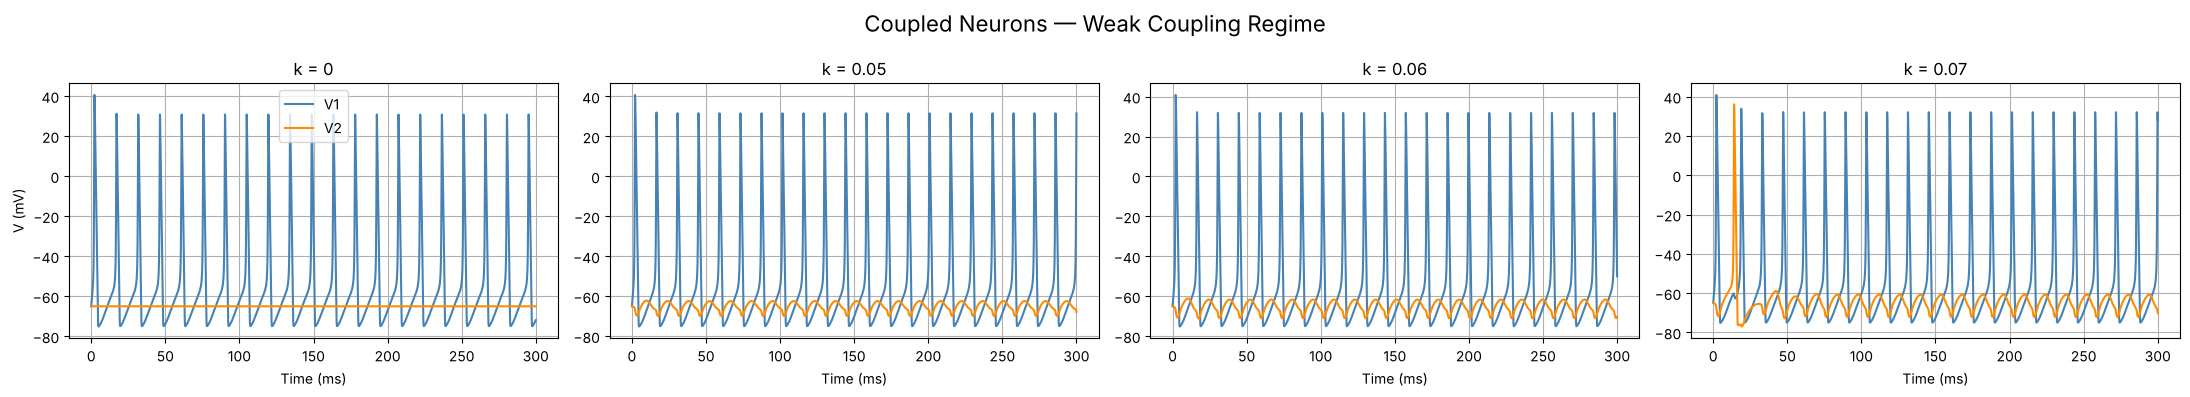

In [20]:
# Figure 1
plot_k_block([0, 0.05, 0.06, 0.07], "Coupled Neurons — Weak Coupling Regime")

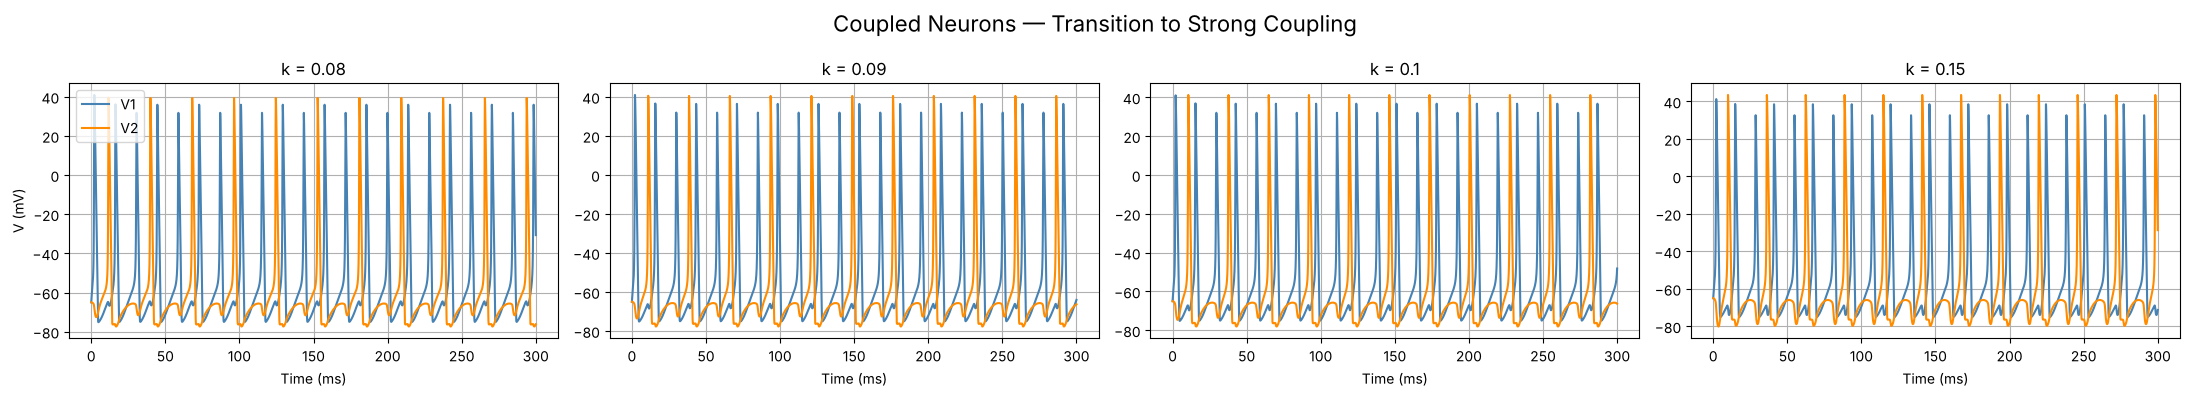

In [21]:
# Figure 2
plot_k_block([0.08, 0.09, 0.10, 0.15], "Coupled Neurons — Transition to Strong Coupling")

**Analysis of the Coupled Neuron Dynamics for Different Values of $k$**

Figures 1 and 2 illustrate how the membrane potentials of the two coupled Hodgkin–Huxley neurons change as the coupling coefficient $k$ increases.
Only neuron 1 receives an external stimulus and fires regularly, while neuron 2 is entirely driven by the coupling current $k(V_1 - V_2)$.


**Figure 1 — Weak Coupling Regime $(k = 0, 0.05, 0.06, 0.07)$**

For very small values of the coupling constant, the second neuron does not receive enough current from the synapse to reach the firing threshold. <br>

•	$k = 0$: the neurons are completely uncoupled, since neuron 1 fires repetitive action potentials, whereas neuron 2 remains at its resting membrane potential. <br>

•	$k = 0.05 – 0.07$:
neuron 2 begins to show subthreshold oscillations, since its membrane potential slightly follows the shape of neuron 1’s action potentials, however the depolarisation is not sufficient to activate sodium channels and generate spikes.

This behaviour corresponds to $weak$ $electrical$ $coupling$, where only a small fraction of the information in neuron 1 is transmitted to neuron 2.

**Figure 2 — Transition to Strong Coupling $(k = 0.08, 0.09, 0.10, 0.15)$**

Figure 2 illustrates how the dynamics of the coupled neurons evolve 
as the coupling coefficient $k$ becomes strong enough to induce 
full spiking in the second neuron.
Increasing the coupling coefficient further produces a qualitative change in the dynamics. <br>

•	$k = 0.08$: the second neuron begins to generate full action potentials. These spikes follow those of neuron 1 with a noticeable but small delay, showing that the coupling current is now sufficient to push the membrane  potential above threshold.  
This marks the $onset$ $of$ $driven$ $firing$. <br>

•	$k ≥ 0.09$: the system enters a $saturated$ $strong–coupling$ $regime$. In this region, neurons 1 and 2 fire almost identically: their spikes have  the same amplitude, shape and timing. Because the membrane potentials 
are nearly superimposed, the difference $V_1 - V_2$ becomes very small, and 
the coupling term $k(V_1 - V_2)$ saturates. For this reason, increasing k further does not produce noticeable changes in the dynamics, making the plots for $k = 0.09, k = 0.10$ and $k = 0.15$ visually almost identical. This reflects the fact that once the second neuron is fully driven and synchronized by the first one, the system behaves as a single effective oscillator, and additional coupling strength has little influence on the trajectory of the membrane potentials.

**Asymmetric Electrical Coupling**

Although gap-junction coupling is typically modelled as a symmetric 
interaction $k_{12} = k_{21}$, several experimental studies have shown 
that electrical synapses can exhibit functional asymmetry under specific 
biological or pathological conditions. Such asymmetry can arise in 
diseases including epilepsy, ischemia, neurodegeneration, or through 
mutations in connexin proteins, which may alter the permeability of 
gap junctions in a direction-dependent manner. Transient asymmetry can 
also result from differences in intracellular calcium concentration, pH, 
or membrane depolarisation, leading to rectification-like behaviours in 
the electrical synapse.

To investigate the dynamical consequences of this phenomenon, we 
extend our model by relaxing the symmetry condition and considering a 
general coupling matrix:

$
k =
\begin{pmatrix}
0 & k_{12} \\
k_{21} & 0
\end{pmatrix},
\qquad
k_{12} \neq k_{21}.
$

In this framework, the influence exerted by neuron 1 on neuron 2 may 
differ from the influence of neuron 2 on neuron 1.  
Simulating a non-symmetric coupling matrix therefore provides a 
meaningful way to study how directional differences in coupling 
strength shape the firing behaviour, information flow, and potential loss 
of synchrony in the coupled neuron system.

To investigate these effects, we simulate the system for four different
asymmetric coupling configurations:

1. $Strongly$ $one-directional$ $(1 → 2)$: $k_{12}=0.10,\; k_{21}=0.00$
2. $Weakly$ $one-directional$ $(1 → 2)$: $k_{12}=0.10,\; k_{21}=0.02$ 
3. $Moderate$ $asymmetry$ $(1 → 2)$: $k_{12}=0.10,\; k_{21}=0.05$  
4. $Moderate$ $asymmetry$ $(2 → 1)$: $k_{12}=0.05,\; k_{21}=0.10$  
5. $Dominance$ $reversed$ $(2 → 1)$: $k_{12}=0.02,\; k_{21}=0.10$

Each case provides insight into how directional coupling influences the
membrane potentials of the two neurons and whether synchronisation is
preserved or disrupted.

In [22]:
def plot_asymmetric_cases(k_list, title):
    n = len(k_list)
    plt.figure(figsize=(22, 4))

    for i, (k12, k21) in enumerate(k_list, start=1):
        
        k_matrix = np.array([[0, k12],
                             [k21, 0]])

        # Simulation
        t_sim, y = euler(
            hh_system_coupled,
            y0,
            t0, t1, dt,
            I_vec,
            k_matrix,
            G_Na, G_K, G_m,
            E_Na, E_K, V_rest,
            C_m
        )

        V1 = y[:, 0]
        V2 = y[:, 1]

        plt.subplot(1, n, i)
        plt.plot(t_sim, V1, label="V1", color="steelblue")
        plt.plot(t_sim, V2, label="V2", color="darkorange")
        plt.title(f"k12={k12}, k21={k21}")
        plt.xlabel("Time (ms)")
        plt.grid(True)
        if i == 1:
            plt.ylabel("V (mV)")
            plt.legend()

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

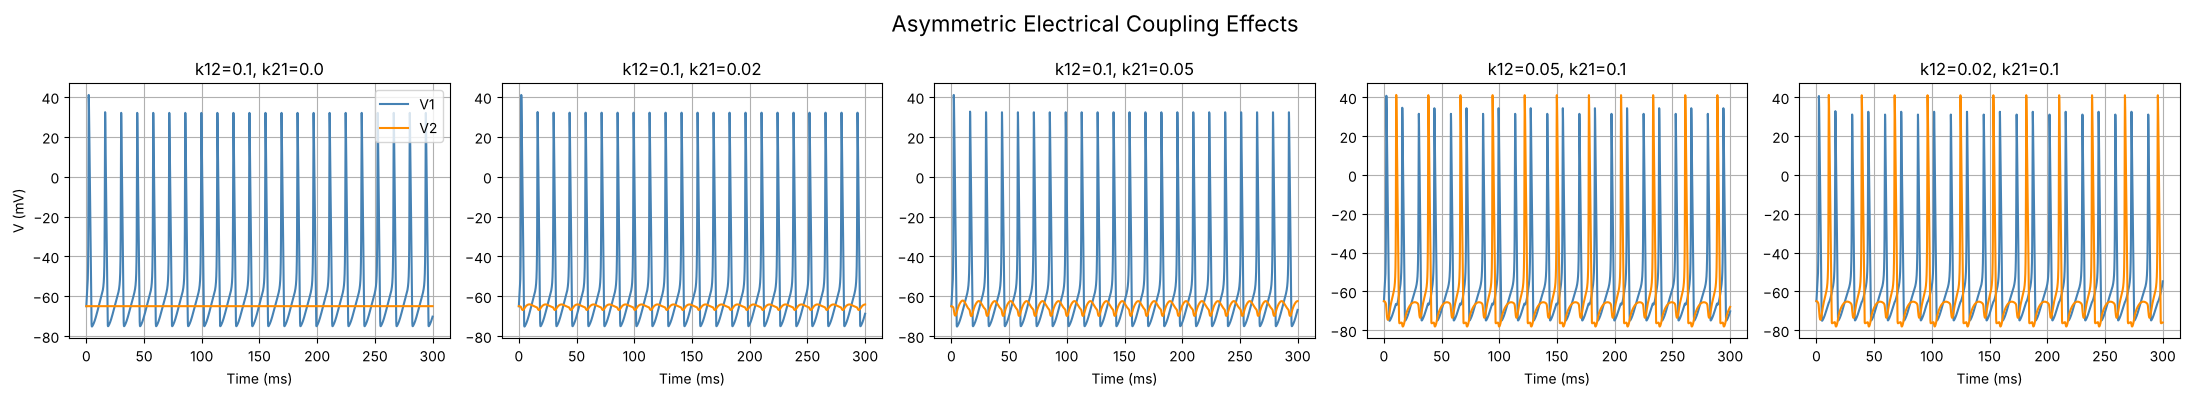

In [23]:
asymmetric_cases = [
    (0.10, 0.00),   
    (0.10, 0.02),  
    (0.10, 0.05),   
    (0.05, 0.10),   
    (0.02, 0.10)    
]

plot_asymmetric_cases(asymmetric_cases,
                      "Asymmetric Electrical Coupling Effects")

The figure shows the membrane potentials of the two neurons for several
asymmetric coupling configurations $(k_{12}, k_{21})$.  
Only neuron 1 receives an external input; neuron 2 is driven exclusively 
through the electrical synapse.

• $k₁₂ = 0.10, k₂₁ = 0.00$: this configuration represents an almost purely unidirectional coupling from neuron 1 to neuron 2. Neuron 1 fires regularly and is completely unaffected by neuron 2, whose membrane potential remains at his resting value. No spiking activity is induced in neuron 2 because the backward current $(2 → 1)$ is absent.

•$k₁₂ = 0.10, k₂₁ = 0.02$: the weak backward coupling remains insufficient to significantly influence neuron 1. Neuron 2 shows slightly larger oscillations but still fails to reach the firing threshold. This case still corresponds to weak and essentially unidirectional 
transmission of information.

• $k₁₂ = 0.10, k₂₁ = 0.05$:  with moderate backward coupling, neuron 2 begins to display stronger depolarisation and more regular subthreshold activity. Neuron 1 remains dominant, but the interaction between the two cells becomes more balanced. Although neuron 2 does not fire, the bidirectional influence is clearly stronger than in the previous cases.

• $k₁₂ = 0.05, k₂₁ = 0.10$: here the asymmetry is reversed, with the backward coupling $k_{21}$ becoming stronger than the forward drive        $k_{12}$. Contrary to the previous cases, neuron 2 is successfully recruited and fires full action potentials synchronized with neuron 1. This suggests that strong backward coupling can lower the effective threshold for synchronization, allowing the follower neuron to fire even when the forward drive is reduced.

• $k₁₂ = 0.02, k₂₁ = 0.10$: in this strongly reversed configuration, the system maintains a $1:1$ synchronized firing state despite the minimal forward coupling. However, neuron 1 is noticeably perturbed by the strong backward current; its spike amplitude varies, and the clean driver–follower relationship is altered. This demonstrates that while strong backward coupling facilitates synchronization, it can also distort the firing stability of the driving neuron (pathological retrograde influence).

Overall, asymmetric coupling reveals that the balance between $k_{12}$ and $k_{21}$ plays a critical role in system dynamics. Crucially, increasing the backward coupling $k_{21}$ does not merely disrupt the driver; it can paradoxically facilitate the recruitment of the second neuron into the firing regime, promoting synchronisation even when the forward drive       $k_{12}$ is weak.

**Analysis: The Role of Backward Coupling in Synchronization**

A counter-intuitive result emerges in the final configurations ($k_{12}=0.05, k_{21}=0.10$): $Neuron$ $2$ $is$ $recruited$ $into$ $firing$ $despite$ $the$ $reduced$ $forward$ $drive$.

One might expect that reducing the forward coupling ($k_{12}: 0.10 \to 0.05$) would prevent Neuron 2 from firing. However, the simultaneous increase in backward coupling ($k_{21}$) facilitates synchronization through the $Loading$ $Effect$:

1.  $Resistive$ $Loading$: A high $k_{21}$ means Neuron 2 acts as a significant electrical load on the driving Neuron 1.
2.  $Spike$ $Broadening$: This load slows down the repolarization phase of Neuron 1, causing its action potential to become wider <br>(increased duration).
3.  $Charge$ $Integration$:  Although the instantaneous current flowing to Neuron 2 is lower (due to low $k_{12}$), the current flows for a *longer duration* due to the widened spike of the driver.
   
Since membrane potential change depends on total charge ($Q = \int I \, dt$), the extended duration allows Neuron 2 to integrate enough current to reach the firing threshold. Thus, **strong backward coupling facilitates synchronization by altering the spike shape of the driver.**

In [24]:
def rk2(f, y0, t0, t1, dt, I_vec, *args):
    """
    Runge–Kutta 2 (midpoint) integration of
        dy/dt = f(y, I_in, *args)
    """

    t = np.arange(t0, t1 + dt, dt)
    y = np.zeros((len(t), len(y0)), dtype=float)

    y[0] = y0

    for i in range(len(t) - 1):
        I_in = I_vec[i]

        # --- Runge–Kutta 2 (Midpoint) ---
        k1 = f(y[i], I_in, *args)
        k2 = f(y[i] + 0.5 * dt * k1, I_in, *args)

        y[i+1] = y[i] + dt * k2

    return t, y


In [25]:
def rk4(f, y0, t0, t1, dt, I_vec, *args):
    """
    Classical Runge–Kutta 4 integration of
        dy/dt = f(y, I_in, *args)

    I_vec must have the same length as t.
    """

    t = np.arange(t0, t1 + dt, dt)
    y = np.zeros((len(t), len(y0)), dtype=float)

    y[0] = y0

    for i in range(len(t) - 1):
        I_in = I_vec[i]

        # --- Runge–Kutta 4 ---
        k1 = f(y[i],                 I_in, *args)
        k2 = f(y[i] + 0.5*dt*k1,     I_in, *args)
        k3 = f(y[i] + 0.5*dt*k2,     I_in, *args)
        k4 = f(y[i] + dt*k3,         I_in, *args)

        y[i+1] = y[i] + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

    return t, y


/tmp/ipykernel_339/2953829247.py:14: RuntimeWarning: overflow encountered in exp
  return 0.01 * (V + 55.0) / (1.0 - np.exp(-(V + 55.0) / 10.0))
/tmp/ipykernel_339/2953829247.py:2: RuntimeWarning: overflow encountered in exp
  return 0.1 * (V + 40.0) / (1.0 - np.exp(-(V + 40.0) / 10.0))
/tmp/ipykernel_339/2953829247.py:11: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0))
/tmp/ipykernel_339/2953829247.py:5: RuntimeWarning: overflow encountered in exp
  return 4.0 * np.exp(-(V + 65.0) / 18.0)
/tmp/ipykernel_339/2953829247.py:8: RuntimeWarning: overflow encountered in exp
  return 0.07 * np.exp(-(V + 65.0)/20.0)
/tmp/ipykernel_339/2496552171.py:6: RuntimeWarning: overflow encountered in scalar power
  return (G_Na * m**3 * h * (E_Na - V) +
/tmp/ipykernel_339/2496552171.py:17: RuntimeWarning: invalid value encountered in scalar multiply
  return alpha_m(V) * (1 - m) - beta_m(V) * m
/tmp/ipykernel_339/2496552171.py:20: RuntimeWarning: invalid val

/tmp/ipykernel_339/2496552171.py:6: RuntimeWarning: invalid value encountered in scalar add
  return (G_Na * m**3 * h * (E_Na - V) +


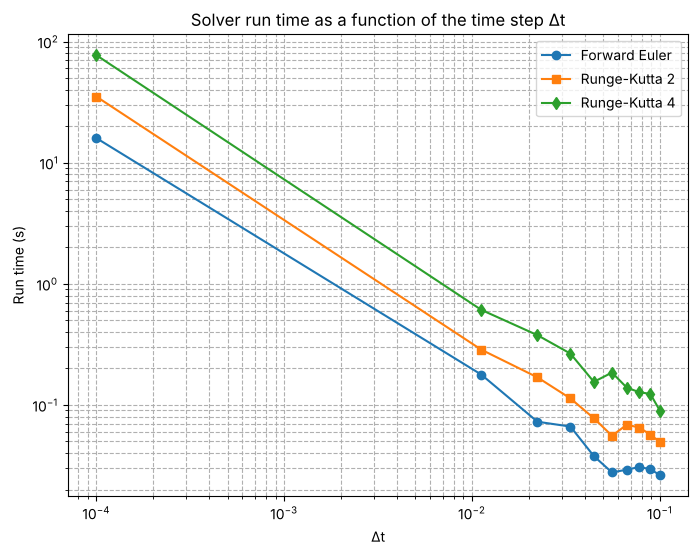

In [26]:
# Linearly spaced time steps from 1e-4 to 0.1 ms
dts = np.linspace(0.0001, 0.1, 10)   # linear spacing, plotted on log axes

V0 = -65.0
n0 = 0.3176769141
m0 = 0.0529324853
h0 = 0.5961207535

y0 = [V0, n0, m0, h0]

t0 = 0.0
t1 = 200.0

times_euler = []
times_rk2 = []
times_rk4 = []

for dt in dts:

    t = np.arange(t0, t1 + dt, dt)

    # Time forward Euler
    t0m = time.time()
    I_vec = I_func(t, True, 7)      

    # Forward Euler integration
    t, y = euler(
        hh_system,
        y0,
        t0, t1, dt,
        I_vec,                 # precomputed input current
        G_Na, G_K, G_m,
        E_Na, E_K, V_rest, C_m
    )
    times_euler.append(time.time() - t0m)

    # Time RK2
    t0m = time.time()
    t, y = rk2(
        hh_system,
        y0,
        t0, t1, dt,
        I_vec,                 # precomputed input current
        G_Na, G_K, G_m,
        E_Na, E_K, V_rest, C_m
    )
    times_rk2.append(time.time() - t0m)

    # Time RK4
    t0m = time.time()
    t, y = rk4(
        hh_system,
        y0,
        t0, t1, dt,
        I_vec,                 # precomputed input current
        G_Na, G_K, G_m,
        E_Na, E_K, V_rest, C_m
    )
    times_rk4.append(time.time() - t0m)

# ============================================================
#  RUN-TIME COMPARISON
# ============================================================

plt.figure(figsize=(8,6))
plt.loglog(dts, times_euler, 'o-', label="Forward Euler")
plt.loglog(dts, times_rk2, 's-', label="Runge-Kutta 2")
plt.loglog(dts, times_rk4, 'd-', label="Runge-Kutta 4")
plt.xlabel("Δt")
plt.ylabel("Run time (s)")
plt.title("Solver run time as a function of the time step Δt")
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()
